### __Anna Kaczyńska, Kamila Mosińska__
## PROJECT 4: Stochastic analysis of an aquifer tracer test
-----

### ABSTRACT


### INTRODUCTION

----------------

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [33]:
class Solver:
    def __init__(self, x0, t0, v=0.5, D=1, alpha_L=2, lamb=0.002, M=1000, L1=50, L2=500):
        self.x0 = x0
        self.t0 = t0
        self.v = v
        self.D = D
        self.alpha_L = alpha_L
        self.lamb = lamb
        self.M = M
        self.L1 = L1
        self.L2 = L2

    def random_walk_1d(self, dt, number_of_steps, N = 20000, decay=True):
        p_decay = 1 - np.exp(-self.lamb*dt)

        trajectories = np.zeros((N, number_of_steps + 1))
        trajectories[:, 0] = self.x0
        alive = np.ones(N, dtype=bool)

        # checkpoint
        alive_count = np.zeros(number_of_steps + 1, dtype=int)
        alive_count[0] = N

        for i in range(number_of_steps):
            random_steps = np.random.normal(0, 1, N)
            trajectories[alive, i+1] = (trajectories[alive, i] + self.v * dt + np.sqrt(2 * self.D * dt) * random_steps[alive])

            if decay:
                decay_events = np.random.random(N) < p_decay
                alive = alive & ~decay_events
            
            trajectories[~alive, i+1] = np.nan

            alive_count[i+1] = np.sum(alive)
            
        return trajectories, alive_count

    def concentration_profile(self, trajectories, N, dt, time_points, bins=100, x_range=(0, 500)):
        profiles = {}

        bin_edges = np.linspace(x_range[0], x_range[1], bins+1)
        bin_centers = (bin_edges[:-1]  + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        for t in time_points:
            step = int(t/dt)
            positions = trajectories[:, step]
            positions = positions[~np.isnan(positions)]

            counts, _ = np.histogram(positions, bins=bin_edges)

            C = (self.M/N) * counts / bin_width
            profiles[t] = C

        return bin_centers, profiles

    def concentration_ananlytical(self, x, t):
        C = (self.M / np.sqrt(4*np.pi*self.D*t)) * np.exp(-((x - self.v*t)**2)/(4*self.D*t) - self.lamb*t)
        return C

    def first_arrival_times(self, trajectories, dt):
        L1 = self.L1

        previous = trajectories[:, :-1]
        current = trajectories[:, 1:]

        crossed = (previous < L1) & (current > L1)
        arrived = np.any(crossed, axis=1)
        first_cross = np.argmax(crossed, axis=1)

        arrival_times = np.full(trajectories.shape[0], np.nan)
        arrival_times[arrived] = (first_cross[arrived] + 1) * dt

        return arrival_times

    def first_arrival_analytical(self, t):
        L1 = self.L1
        f = L1/(np.sqrt(4*np.pi*self.D*t**3)) * np.exp(-((L1-self.v*t)**2)/(4*self.D*t))
        return f

In [34]:
def plot_particle_position(trajectories, dt, times=[40, 120, 300]):

    plt.figure(figsize=(10, 5))

    colors = ['tab:blue', 'tab:orange', 'tab:green']

    for t, color in zip(times, colors):

        step = int(t / dt)
        positions = trajectories[:, step]

        positions = positions[~np.isnan(positions)]
        y = np.random.uniform(0, 1, len(positions))

        plt.scatter(
            positions,
            y,
            s=2,
            alpha=0.4,
            color=color,
            label=f't = {t} days'
        )

    plt.axvline(50, color='red', linestyle='--')

    plt.xlabel('x [m]')
    plt.legend()
    plt.tight_layout()
    plt.show()

Initial number of particles: 20000
Surviving particles: 11020
Decayed particles: 8980
Percentage decayed: 44.90%


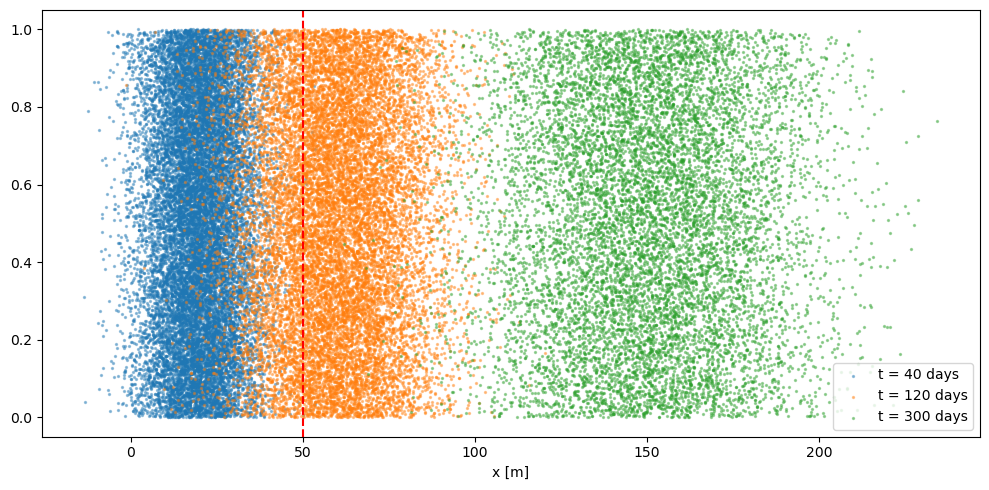

In [35]:
dt = 0.5
number_of_steps = 600  # 300 days
N = 20000

solver = Solver(x0=0, t0=0)

trajectories, alive_count = solver.random_walk_1d(
    dt=dt,
    number_of_steps=number_of_steps,
    N=N
)

print(f"Initial number of particles: {N}")
print(f"Surviving particles: {alive_count[-1]}")
print(f"Decayed particles: {N - alive_count[-1]}")
print(f"Percentage decayed: {(N - alive_count[-1]) / N * 100:.2f}%")

plot_particle_position(trajectories, dt)

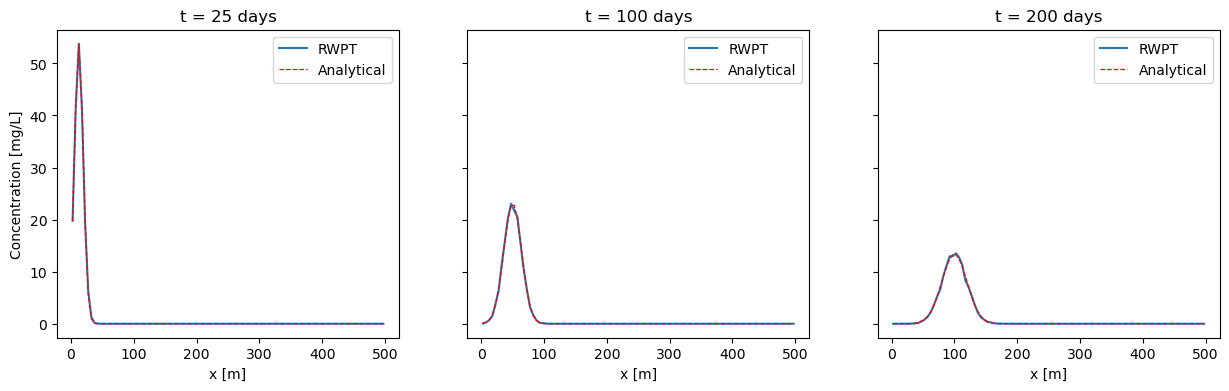

In [36]:
time_points = [25, 100, 200]

x, profiles = solver.concentration_profile(
    trajectories=trajectories,
    N=N,
    dt=dt,
    time_points=time_points,
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, t in zip(axes,time_points):
    ax.plot(x, profiles[t], label="RWPT", color="tab:blue")

    C_analytical = solver.concentration_ananlytical(x, t)
    ax.plot(x, C_analytical, "--", linewidth=0.9, label="Analytical", color="red")

    ax.set_title(f"t = {t} days")
    ax.set_xlabel("x [m]")
    ax.legend()

axes[0].set_ylabel("Concentration [mg/L]")
plt.show()

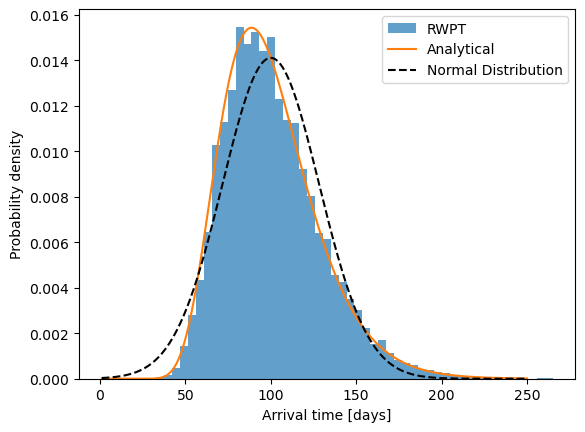

In [40]:
trajectories_no_decay, _ = solver.random_walk_1d(dt=0.5, number_of_steps=600, N=20000, decay=False)

arrival_times = solver.first_arrival_times(trajectories_no_decay, dt)
valid_arrivals = arrival_times[~np.isnan(arrival_times)]

t = np.linspace(1, 250, 1000)
f_analytical = solver.first_arrival_analytical(t)

mean = solver.L1 / solver.v
variance = 2 * solver.D * solver.L1 / solver.v**3
std = np.sqrt(variance)
normal_distribution = norm.pdf(t, mean, std)

plt.figure()
plt.hist(valid_arrivals, bins=50, density=True, alpha=0.7, label="RWPT")
plt.plot(t, f_analytical, label="Analytical")
plt.plot(t, normal_distribution, linestyle='--', color="black", label="Normal Distribution")
plt.xlabel("Arrival time [days]")
plt.ylabel("Probability density")
plt.legend()
plt.show()

TO DO:  Is the arrival time normally distributed? Explain.